11/3/2026 Gottlieb

The purpose of this notebook is to recreate Vásquez and Farinelli's 21-asset simulation using the functions developed in the previous notebooks. We simulate prices, estimate the two null directions from the first 100 price observations, and compare the detector with the known squared arbitrage drift. We then check the same signal in each pricing unit.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from arbitrage_functions import (
    align_directions,
    brownian_increments,
    check_numeraires,
    estimate_directions,
    simulate_gbm,
)

There are $N=21$ assets (cash and 20 risky assets), driven by $d=18$ independent Brownian shocks. This gives $k=N-d-1=2$ zero-cost null directions. Following section 4.3, draw:
$$\sigma_i^a\in[-10^{-3},10^{-3}],\qquad \beta^a\in[-10^{-4},10^{-4}],\qquad \alpha^A\in[-10^{-4},10^{-4}].$$
Here $\beta^a$ is the price of risk and $\alpha^A$ is the drift along null direction $A$. Cash has zero volatility. We use 200 steps with $\Delta t=1$; the seed and initial prices are our choices.


In [2]:
N = 21
n_shocks = 18
k = 2
n_steps = 200
dt = 1.0
assets = ["Cash"] + [f"Asset {i}" for i in range(1, N)]
rng = np.random.default_rng(42)

sigma = np.zeros((N, n_shocks))
sigma[1:] = rng.uniform(-1e-3, 1e-3, size=(N - 1, n_shocks))
beta = rng.uniform(-1e-4, 1e-4, size=n_shocks)
arbitrage_drifts = rng.uniform(-1e-4, 1e-4, size=k)

Omega = sigma @ sigma.T
J, _ = estimate_directions(Omega, k)
J = align_directions(J)

We then construct the drift from the volatility exposures and null directions, then subtract the cash entry so that $\alpha_0=0$:
$$b=\sigma\beta+J\alpha^{\mathrm{null}},\qquad \alpha=b-b_0\mathbf{1}.$$
Because $J^T\mathbf{1}=0$ and $J^T\sigma=0$, this preserves the chosen null drifts. The known signal to recover is
$$\mathcal A^2=\sum_{A=1}^2(\alpha^A)^2.$$


In [3]:
raw_drift = sigma @ beta + J @ arbitrage_drifts
alpha = raw_drift - raw_drift[0]
true_signal = arbitrage_drifts @ arbitrage_drifts

print(f"True squared arbitrage drift: {true_signal:.6e}")

True squared arbitrage drift: 2.654792e-09


Generate the Brownian increments and simulate GBM prices. All assets start at 1; cash stays at 1. Plot the 20 risky assets in log prices.


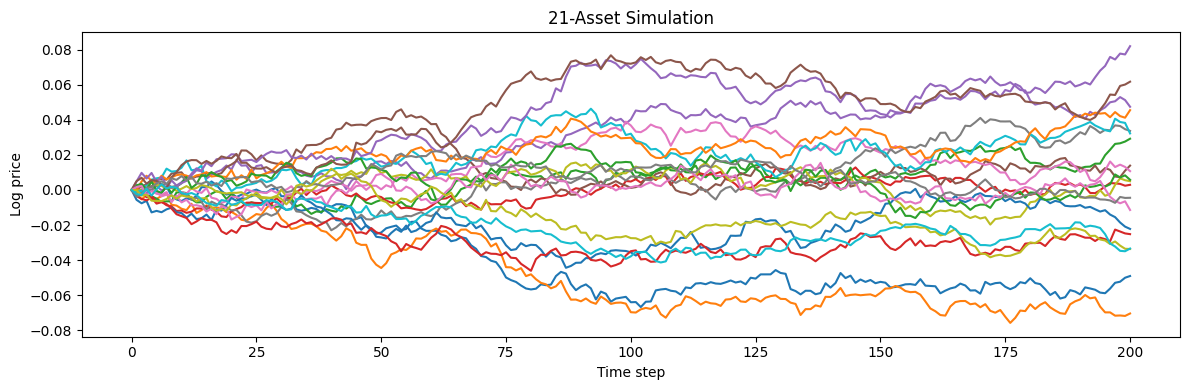

In [4]:
dW = brownian_increments(n_steps, n_shocks, dt, rng)
prices = simulate_gbm(np.ones(N), alpha, sigma, dt, dW, assets)

fig, ax = plt.subplots(1, 1, figsize=(12, 4))
ax.plot(prices.index, np.log(prices.iloc[:, 1:]))
ax.set_title("21-Asset Simulation")
ax.set_xlabel("Time step")
ax.set_ylabel("Log price")
plt.tight_layout()
plt.show()

Next, let's estimate the two null directions from the first 100 price observations (99 returns) and hold that basis fixed. We apply it to subsequent simple returns and multiply consecutive drift estimates:
$$\hat{\mathcal A^2}(t+1)=\sum_{A=1}^2\hat\alpha^A(t)\hat\alpha^A(t+1).$$
The first drift estimate is at step 100 and the first detector value at step 101. We also repeat in every pricing unit to check numéraire invariance at this finite time step.


In [5]:
L = 99
fixed = check_numeraires(prices, L, dt, k=k, rolling=False)
cash_run = fixed["runs"]["Cash"]
fixed_summary = fixed["summary"]

mean_detector = cash_run["results"]["Detector"].mean()
signal_summary = pd.Series({
    "True squared drift": true_signal,
    "Cash mean detector": mean_detector,
    "Relative error of cash mean": (mean_detector - true_signal) / true_signal,
    "Mean range across pricing units": fixed_summary["Range"].mean(),
    "Largest range across pricing units": fixed_summary["Range"].max(),
})
print(signal_summary.to_string(float_format="{:.6e}".format))


True squared drift                   2.654792e-09
Cash mean detector                   2.732388e-09
Relative error of cash mean          2.922865e-02
Mean range across pricing units      3.392149e-11
Largest range across pricing units   6.554180e-11
